# **PROJET DE CLASSIFICATION BINAIRE DE PATIENTS**
## Master IAOC - Université Ibn Tofail
## Module : Techniques d'Intelligence Artificielle

**- Dataset :** Multi-Class Chronic Disease Data Warehouse.

**- Objectif :** Développer un modèle de classification binaire permettant de prédire si un patient est « Normal » ou « Abnormal » (c’est-à-dire souffrant d’au moins une maladie chronique parmi le diabète, l’hypertension ou une maladie cardiaque) à partir de données démographiques, anthropométriques, de mode de vie et de mesures cliniques, tout en identifiant les facteurs les plus importants pour la prédiction.

### **Notebook 2 :** Comparaison et optimisation d'autres modèles

### **Plan de travail :**
1. Chargement des données prétraitées
2. Définition des utilitaires (bootstrap CI, seuil Youden, évaluation)
3. Modèles baseline (LR, SVM RBF, XGBoost, LightGBM)
4. Cross-Validation stratifiée et détection overfitting
5. Optimisation avec RandomizedSearchCV
6. Évaluation finale de tous les modèles optimisés
7. Tableau récapitulatif final
8. Visualisations comparatives
9. Vérification overfitting -AUC TRAIN vs AUC TEST (modèles finaux)
10. Sauvegarde

## IMPORTATIONS

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                      RandomizedSearchCV)
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve, average_precision_score, 
    matthews_corrcoef, cohen_kappa_score, brier_score_loss, accuracy_score, precision_score, recall_score, f1_score)
from sklearn.utils import resample
import joblib

## 1. CHARGEMENT DES DONNÉES PRÉTRAITÉES

Les fichiers CSV proviennent du notebook précédent (notebook_1.ipynb). Ils contiennent les données après :

- suppression des colonnes à risque de leakage
  
- encodage des variables catégorielles

- split stratifié 80/20

- standardisation (StandardScaler fitté sur X_train uniquement)

  
- sélection des 20 meilleures features (SelectKBest / f_classif)

Aucune standardisation supplémentaire ne sera appliquée aux modèles tree-based (XGBoost, LightGBM) car ils n'en ont pas besoin. Pour LR et SVM, un StandardScaler est intégré dans un Pipeline.

In [4]:
X_train = pd.read_csv("X_train.csv")
X_test  = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze()
y_test  = pd.read_csv("y_test.csv").squeeze()

print("Données chargées")
print(f"X_train : {X_train.shape}  |  X_test : {X_test.shape}")
print(f"Distribution train - Normal: {(y_train==0).sum()} | Abnormal: {(y_train==1).sum()}")
print(f"Distribution test - Normal: {(y_test==0).sum()}  | Abnormal: {(y_test==1).sum()}")

# Ratio classes (utile pour scale_pos_weight de XGBoost)
# scale_pos_weight = nb_négatifs / nb_positifs quand négatifs < positifs permer de rééquilibrer le poids accordé à la classe minoritaire (Normal)
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"\nRatio négatifs/positifs (scale_pos_weight XGBoost) : {scale_pos_weight:.4f}")

Données chargées
X_train : (222960, 20)  |  X_test : (55741, 20)
Distribution train - Normal: 83718 | Abnormal: 139242
Distribution test - Normal: 20930  | Abnormal: 34811

Ratio négatifs/positifs (scale_pos_weight XGBoost) : 0.6012


## 2. FONCTIONS UTILITAIRES

In [5]:
# Calcule la moyenne et l'intervalle de confiance d'une métrique par rééchantillonnage bootstrap.
def bootstrap_ci(y_true, y_proba, metric_fn, n=1000, ci=0.95):
    scores  = []
    idx_all = np.arange(len(y_true))
    for _ in range(n):
        idx = resample(idx_all, replace=True)
        try:
            scores.append(metric_fn(np.array(y_true)[idx],
                                    np.array(y_proba)[idx]))
        except Exception:
            continue
    alpha = (1 - ci) / 2
    return (np.mean(scores),
            np.percentile(scores, alpha * 100),
            np.percentile(scores, (1 - alpha) * 100))

In [6]:
# Calcule le seuil optimal (Youden Index) à partir des prédictions sur X_train.
def best_threshold_on_train(model, X_tr, y_tr):
    y_proba_tr = model.predict_proba(X_tr)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_tr, y_proba_tr)
    youden = tpr - fpr
    return float(thresholds[np.argmax(youden)])

In [7]:
# Entraîne le modèle sur (X_tr, y_tr), puis évalue sur (X_te, y_te).
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, best_params=None):
    model.fit(X_tr, y_tr)

    # Seuil optimal sur train
    threshold = best_threshold_on_train(model, X_tr, y_tr)

    # Prédictions sur test
    y_proba = model.predict_proba(X_te)[:, 1]
    y_pred  = (y_proba >= threshold).astype(int)

    # Métriques
    auc  = roc_auc_score(y_te, y_proba)
    ap   = average_precision_score(y_te, y_proba)
    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec  = recall_score(y_te, y_pred, zero_division=0)
    f1   = f1_score(y_te, y_pred, zero_division=0)
    mcc  = matthews_corrcoef(y_te, y_pred)
    kap  = cohen_kappa_score(y_te, y_pred)
    bri  = brier_score_loss(y_te, y_proba)

    cm             = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sensitivity    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity    = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    # IC bootstrap 95%
    auc_mean, auc_lo, auc_hi = bootstrap_ci(y_te, y_proba, roc_auc_score)
    ap_mean,  ap_lo,  ap_hi  = bootstrap_ci(y_te, y_proba,
                                             average_precision_score)
    mcc_fn = lambda yt, yp: matthews_corrcoef(
        yt, (yp >= threshold).astype(int))
    mcc_mean, mcc_lo, mcc_hi = bootstrap_ci(y_te, y_proba, mcc_fn)

    print(f"\n{'='*65}")
    print(f"  {name}")
    if best_params:
        print(f"  Hyperparamètres : {best_params}")
    print(f"{'='*65}")
    print(f"  Seuil (Youden, train) : {threshold:.3f}")
    print(f"  AUC-ROC      : {auc:.4f}  [IC 95% : {auc_lo:.4f} – {auc_hi:.4f}]")
    print(f"  AUC-PR       : {ap:.4f}   [IC 95% : {ap_lo:.4f}  – {ap_hi:.4f}]")
    print(f"  Accuracy     : {acc:.4f}")
    print(f"  Precision    : {prec:.4f}")
    print(f"  Recall       : {rec:.4f}")
    print(f"  F1-Score     : {f1:.4f}")
    print(f"  MCC          : {mcc:.4f}  [IC 95% : {mcc_lo:.4f} – {mcc_hi:.4f}]")
    print(f"  Cohen Kappa  : {kap:.4f}")
    print(f"  Brier Score  : {bri:.4f}")
    print(f"  Sensibilité  : {sensitivity:.4f}")
    print(f"  Spécificité  : {specificity:.4f}")
    print(f"\n{classification_report(y_te, y_pred, target_names=['Normal','Abnormal'])}")
    print(f"  Matrice de confusion :\n{cm}")

    return {
        "Modèle"       : name,
        "Seuil"        : round(threshold, 3),
        "AUC-ROC"      : round(auc, 4),
        "AUC-PR"       : round(ap, 4),
        "Accuracy"     : round(acc, 4),
        "Precision"    : round(prec, 4),
        "Recall"       : round(rec, 4),
        "F1-Score"     : round(f1, 4),
        "MCC"          : round(mcc, 4),
        "Kappa"        : round(kap, 4),
        "Brier"        : round(bri, 4),
        "Sensibilité"  : round(sensitivity, 4),
        "Spécificité"  : round(specificity, 4),
        "AUC IC95"     : f"{auc_lo:.4f}–{auc_hi:.4f}",
        "AUC-PR IC95"  : f"{ap_lo:.4f}–{ap_hi:.4f}",
        "MCC IC95"     : f"{mcc_lo:.4f}–{mcc_hi:.4f}",
        "_model"       : model,      
        "_threshold"   : threshold,  
        "_cm"          : cm,         
    }

##  3. DÉFINITION DES MODÈLES BASELINE

**Notes sur les choix d'architecture :**

- Logistic Regression et SVM RBF : enveloppés dans un Pipeline avec StandardScaler car ces modèles sont sensibles à l'échelle des features. (XGBoost et LightGBM sont des tree-based donc insensibles à l'échelle)

- class_weight="balanced" : gère le déséquilibre de classes (62/38) sans suréchantillonnage artificiel (SMOTE écarté car déséquilibre modéré).

- SVM RBF : entraîné sur un sous-ensemble de 30 000 observations car la complexité mémoire d'un SVM kernel est O(n²). Sur environs 220 000 lignes il ne converge pas en temps raisonnable. Ses métriques sont donc indicatives et non directement comparables aux autres modèles entraînés sur le jeu complet.

In [8]:
# Sous-ensemble pour SVM
SVM_SUBSET = 30_000
idx_svm = np.random.default_rng(42).choice(len(X_train), SVM_SUBSET, replace=False)
X_train_svm = X_train.iloc[idx_svm].reset_index(drop=True)
y_train_svm = y_train.iloc[idx_svm].reset_index(drop=True)

MODELS = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            solver="lbfgs",
            random_state=42
        ))
    ]),

    # SVM entraîné uniquement sur X_train_svm (30 000 lignes)
    "SVM RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", CalibratedClassifierCV(
            SVC(kernel="rbf", class_weight="balanced",
                probability=False, random_state=42),
            method="isotonic", cv=3
        ))
    ]),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        use_label_encoder=False,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=63,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbose=-1
    ),
}

print(f"\nModèles définis : {list(MODELS.keys())} ───")
print(f"SVM RBF entraîné sur {SVM_SUBSET:,} observations (sous-ensemble)")


Modèles définis : ['Logistic Regression', 'SVM RBF', 'XGBoost', 'LightGBM'] ───
SVM RBF entraîné sur 30,000 observations (sous-ensemble)


## 4. CROSS-VALIDATION STRATIFIÉE ET DÉTECTION DE L'OVERFITTING

La CV est réalisée UNIQUEMENT sur X_train pour chaque modèle. le X_test n'est jamais touché à cette étape. Le Critère de diagnostic :
Gap (Train AUC - Val AUC) > 0.05 entraine un surapprentissage potentiel

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\nCross-Validation Stratifiée (5-Fold)")
print(f"{'─'*72}")
print(f"{'Modèle':<22}  {'Train AUC':>10}  {'Val AUC':>10}  "
      f"{'Gap':>8}  {'Std':>6}  Verdict")
print(f"{'─'*72}")

cv_summary = []
for name, model in MODELS.items():
    # SVM 
    X_cv = X_train_svm if name == "SVM RBF" else X_train
    y_cv = y_train_svm if name == "SVM RBF" else y_train

    cv_res = cross_validate(
        model, X_cv, y_cv,
        cv=skf,
        scoring={"auc": "roc_auc"},
        n_jobs=-1,
        return_train_score=True
    )
    train_auc = cv_res["train_auc"].mean()
    val_auc   = cv_res["test_auc"].mean()
    val_std   = cv_res["test_auc"].std()
    gap       = train_auc - val_auc
    flag      = "OVERFITTING !" if gap > 0.05 else "OK"

    note = " (sous-ens. 30K)" if name == "SVM RBF" else ""
    print(f"{name:<22}  {train_auc:>10.4f}  {val_auc:>10.4f}  "
          f"{gap:>8.4f}  {val_std:>6.4f}  {flag}{note}")

    cv_summary.append({
        "Modèle"    : name,
        "Train AUC" : round(train_auc, 4),
        "Val AUC"   : round(val_auc, 4),
        "Gap"       : round(gap, 4),
        "Std"       : round(val_std, 4),
        "Verdict"   : flag.strip()
    })

print(f"{'─'*72}")
df_cv = pd.DataFrame(cv_summary).set_index("Modèle")
print("\n", df_cv)


Cross-Validation Stratifiée (5-Fold)
────────────────────────────────────────────────────────────────────────
Modèle                   Train AUC     Val AUC       Gap     Std  Verdict
────────────────────────────────────────────────────────────────────────
Logistic Regression         0.8545      0.8544    0.0001  0.0008  OK
SVM RBF                     0.9442      0.9225    0.0217  0.0016  OK (sous-ens. 30K)
XGBoost                     0.9557      0.9387    0.0171  0.0007  OK
LightGBM                    0.9708      0.9395    0.0314  0.0003  OK
────────────────────────────────────────────────────────────────────────

                      Train AUC  Val AUC     Gap     Std Verdict
Modèle                                                         
Logistic Regression     0.8545   0.8544  0.0001  0.0008      OK
SVM RBF                 0.9442   0.9225  0.0217  0.0016      OK
XGBoost                 0.9557   0.9387  0.0171  0.0007      OK
LightGBM                0.9708   0.9395  0.0314  0.0003

## 5. OPTIMISATION DES HYPERPARAMÈTRES AVEC RandomizedSearchCV

In [10]:
skf_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_spaces = {
    "Logistic Regression": {
        "estimator": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, random_state=42,
                                       solver="saga"))
        ]),
        "params": {
            "clf__C"           : [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
            "clf__penalty"     : ["l1", "l2", "elasticnet"],
            "clf__class_weight": ["balanced", None],
            "clf__l1_ratio"    : [0.0, 0.25, 0.5, 0.75, 1.0],
        },
        "X": X_train,
        "y": y_train,
    },

    "XGBoost": {
        "estimator": XGBClassifier(
            eval_metric="logloss", use_label_encoder=False,
            random_state=42, n_jobs=-1
        ),
        "params": {
            "n_estimators"     : [100, 200, 300, 400],
            "learning_rate"    : [0.01, 0.05, 0.1, 0.2],
            "max_depth"        : [4, 6, 8, 10],
            "subsample"        : [0.6, 0.7, 0.8, 0.9],
            "colsample_bytree" : [0.6, 0.7, 0.8, 1.0],
            "scale_pos_weight" : [scale_pos_weight, 1.0],
            "min_child_weight" : [1, 3, 5],
            "gamma"            : [0, 0.1, 0.3, 0.5],
        },
        "X": X_train,
        "y": y_train,
    },

    "LightGBM": {
        "estimator": LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
        "params": {
            "n_estimators"     : [100, 200, 300, 400],
            "learning_rate"    : [0.01, 0.05, 0.1, 0.2],
            "num_leaves"       : [31, 63, 127, 255],
            "max_depth"        : [-1, 6, 10, 15],
            "min_child_samples": [10, 20, 30, 50],
            "subsample"        : [0.6, 0.8, 1.0],
            "colsample_bytree" : [0.6, 0.8, 1.0],
            "class_weight"     : ["balanced"],
            "reg_alpha"        : [0, 0.1, 0.5, 1.0],
            "reg_lambda"       : [0, 0.1, 0.5, 1.0],
        },
        "X": X_train,
        "y": y_train,
    },
}

best_params_dict  = {}
best_estimators   = {}

for name, config in param_spaces.items():
    print(f"\nTuning : {name} ...")
    search = RandomizedSearchCV(
        estimator           = config["estimator"],
        param_distributions = config["params"],
        n_iter              = 30,
        cv                  = skf_tune,
        scoring             = "roc_auc",
        n_jobs              = -1,
        random_state        = 42,
        verbose             = 0,
        refit               = True
    )
    search.fit(config["X"], config["y"])

    best_params_dict[name] = search.best_params_
    best_estimators[name]  = search.best_estimator_

    print(f"  Meilleur AUC-ROC (CV) : {search.best_score_:.4f}")
    print(f"  Meilleurs hyperparamètres : {search.best_params_}")

# SVM avec paramètres fixes (pas de RandomizedSearch)
print(f"\nSVM RBF - paramètres fixes (pas de tuning sur sous-ensemble)")
svm_fixed = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", CalibratedClassifierCV(
        SVC(kernel="rbf", C=1.0, gamma="scale",
            class_weight="balanced",
            probability=False, random_state=42),
        method="isotonic", cv=3
    ))
])
svm_fixed.fit(X_train_svm, y_train_svm)
best_estimators["SVM RBF"]  = svm_fixed
best_params_dict["SVM RBF"] = {"C": 1.0, "gamma": "scale",
                                "note": "paramètres fixes, sous-ens. 30K"}

print(" SVM RBF prêt.")
print("\nTuning terminé pour tous les modèles.")


Tuning : Logistic Regression ...
  Meilleur AUC-ROC (CV) : 0.8548
  Meilleurs hyperparamètres : {'clf__penalty': 'l2', 'clf__l1_ratio': 0.5, 'clf__class_weight': None, 'clf__C': 5}

Tuning : XGBoost ...
  Meilleur AUC-ROC (CV) : 0.9394
  Meilleurs hyperparamètres : {'subsample': 0.9, 'scale_pos_weight': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 0.6}

Tuning : LightGBM ...
  Meilleur AUC-ROC (CV) : 0.9396
  Meilleurs hyperparamètres : {'subsample': 0.6, 'reg_lambda': 0.5, 'reg_alpha': 0.5, 'num_leaves': 255, 'n_estimators': 100, 'min_child_samples': 30, 'max_depth': 15, 'learning_rate': 0.1, 'colsample_bytree': 0.8, 'class_weight': 'balanced'}

SVM RBF - paramètres fixes (pas de tuning sur sous-ensemble)
 SVM RBF prêt.

Tuning terminé pour tous les modèles.


## 6. ÉVALUATION FINALE DE TOUS LES MODÈLES OPTIMISÉS

In [11]:
all_results = []
for name, model in best_estimators.items():
    print(f"\n{'▶'*3}  Évaluation : {name}")

    # SVM évalué sur X_test complet (généralisé depuis 30K train)
    X_tr = X_train_svm if name == "SVM RBF" else X_train
    y_tr = y_train_svm if name == "SVM RBF" else y_train

    result = evaluate_model(
        name, model,
        X_tr, y_tr,
        X_test, y_test,
        best_params=best_params_dict.get(name)
    )
    all_results.append(result)


▶▶▶  Évaluation : Logistic Regression

  Logistic Regression
  Hyperparamètres : {'clf__penalty': 'l2', 'clf__l1_ratio': 0.5, 'clf__class_weight': None, 'clf__C': 5}
  Seuil (Youden, train) : 0.681
  AUC-ROC      : 0.8570  [IC 95% : 0.8543 – 0.8602]
  AUC-PR       : 0.9126   [IC 95% : 0.9102  – 0.9148]
  Accuracy     : 0.7495
  Precision    : 0.8669
  Recall       : 0.7075
  F1-Score     : 0.7792
  MCC          : 0.5104  [IC 95% : 0.5036 – 0.5177]
  Cohen Kappa  : 0.4966
  Brier Score  : 0.1486
  Sensibilité  : 0.7075
  Spécificité  : 0.8194

              precision    recall  f1-score   support

      Normal       0.63      0.82      0.71     20930
    Abnormal       0.87      0.71      0.78     34811

    accuracy                           0.75     55741
   macro avg       0.75      0.76      0.74     55741
weighted avg       0.78      0.75      0.75     55741

  Matrice de confusion :
[[17149  3781]
 [10181 24630]]

▶▶▶  Évaluation : XGBoost

  XGBoost
  Hyperparamètres : {'subsamp

## 7. TABLEAU RÉCAPITULATIF FINAL

In [12]:
# Extraction des colonnes métriques 
metric_keys = [k for k in all_results[0].keys() if not k.startswith("_")]
df_results  = pd.DataFrame(
    [{k: r[k] for k in metric_keys} for r in all_results]
).set_index("Modèle").sort_values("AUC-ROC", ascending=False)

cols_key = ["AUC-ROC", "AUC IC95", "AUC-PR", "Accuracy",
            "Sensibilité", "Spécificité", "MCC", "MCC IC95",
            "Kappa", "Brier"]

print("\n" + "="*100)
print("  TABLEAU RÉCAPITULATIF : Comparaison des modèles optimisés")
print("="*100)
print(df_results[cols_key].to_string())


  TABLEAU RÉCAPITULATIF : Comparaison des modèles optimisés
                     AUC-ROC       AUC IC95  AUC-PR  Accuracy  Sensibilité  Spécificité     MCC       MCC IC95   Kappa   Brier
Modèle                                                                                                                        
XGBoost               0.9400  0.9382–0.9418  0.9632    0.8463       0.8591       0.8250  0.6768  0.6705–0.6831  0.6761  0.0881
LightGBM              0.9391  0.9372–0.9409  0.9626    0.8426       0.8530       0.8253  0.6700  0.6635–0.6765  0.6690  0.0921
SVM RBF               0.9221  0.9198–0.9241  0.9496    0.8381       0.8507       0.8171  0.6601  0.6539–0.6662  0.6592  0.0992
Logistic Regression   0.8570  0.8543–0.8602  0.9126    0.7495       0.7075       0.8194  0.5104  0.5036–0.5177  0.4966  0.1486


## 8. VISUALISATIONS COMPARATIVES

In [13]:
colors = ["#2196F3", "#FF5722", "#4CAF50", "#9C27B0"]

#### 8.1. Courbes ROC + Barplot AUC/MCC

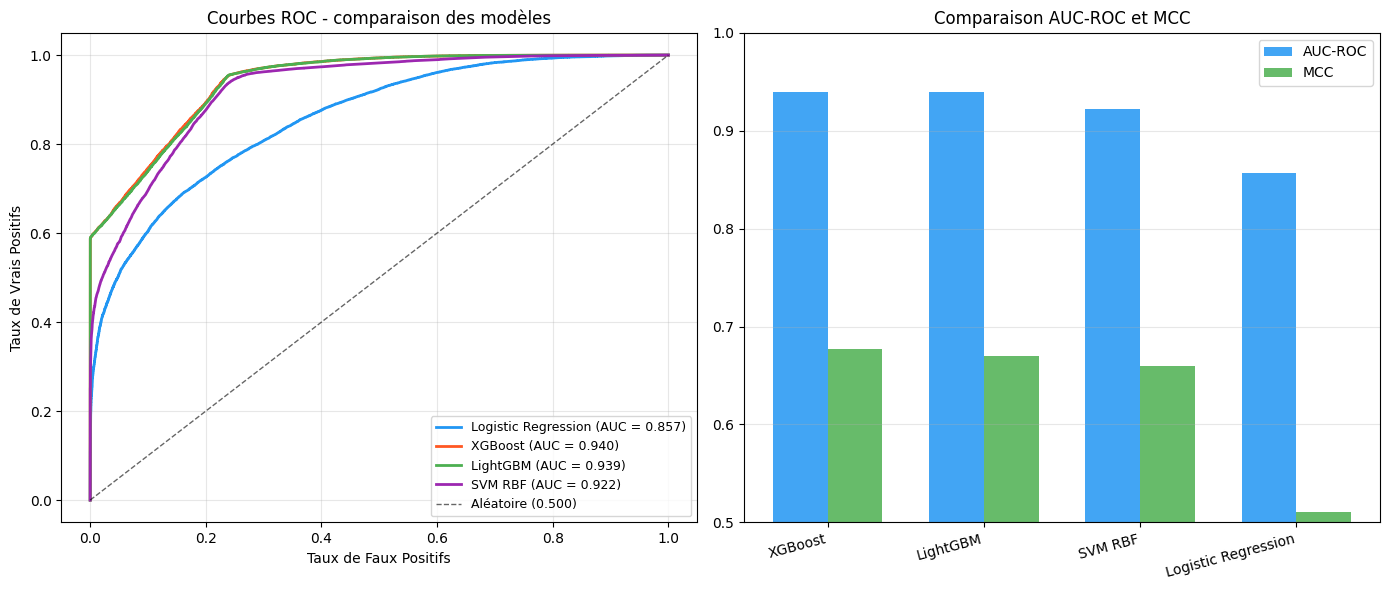

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
for result, color in zip(all_results, colors):
    model  = result["_model"]
    name   = result["Modèle"]
    auc    = result["AUC-ROC"]
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, lw=2, color=color,
            label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Aléatoire (0.500)")
ax.set_xlabel("Taux de Faux Positifs")
ax.set_ylabel("Taux de Vrais Positifs")
ax.set_title("Courbes ROC - comparaison des modèles")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax2 = axes[1]
names = df_results.index.tolist()
x     = np.arange(len(names))
w     = 0.35
ax2.bar(x - w/2, df_results["AUC-ROC"], w, label="AUC-ROC",
        color="#2196F3", alpha=0.85)
ax2.bar(x + w/2, df_results["MCC"],     w, label="MCC",
        color="#4CAF50", alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(names, rotation=15, ha="right")
ax2.set_ylim(0.5, 1.0)
ax2.set_title("Comparaison AUC-ROC et MCC")
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("comparaison_roc_mcc.png", dpi=150, bbox_inches="tight")
plt.show()

#### 8.2. Matrices de confusion

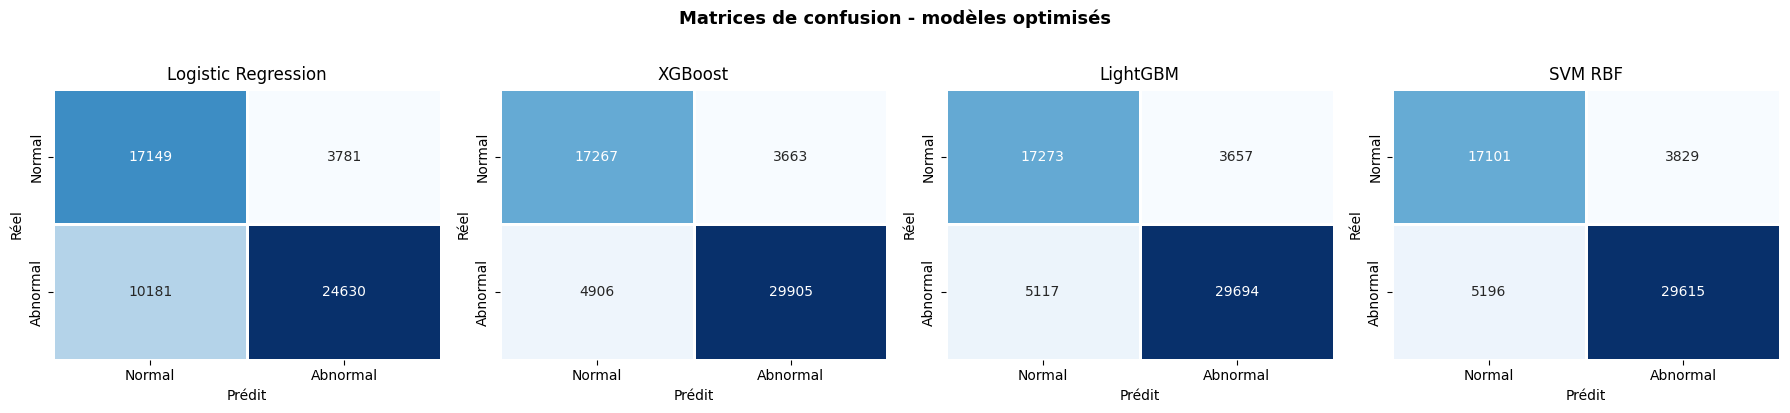

In [15]:
n = len(all_results)
fig2, axes2 = plt.subplots(1, n, figsize=(4.5 * n, 4))
if n == 1:
    axes2 = [axes2]

for ax, result in zip(axes2, all_results):
    cm   = result["_cm"]
    name = result["Modèle"]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'Abnormal'],
                yticklabels=['Normal', 'Abnormal'],
                ax=ax, linewidths=1)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_title(f"{name}")

fig2.suptitle("Matrices de confusion - modèles optimisés", fontsize=13,
              fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

#### 8.3. Radar chart - profil de chaque modèle

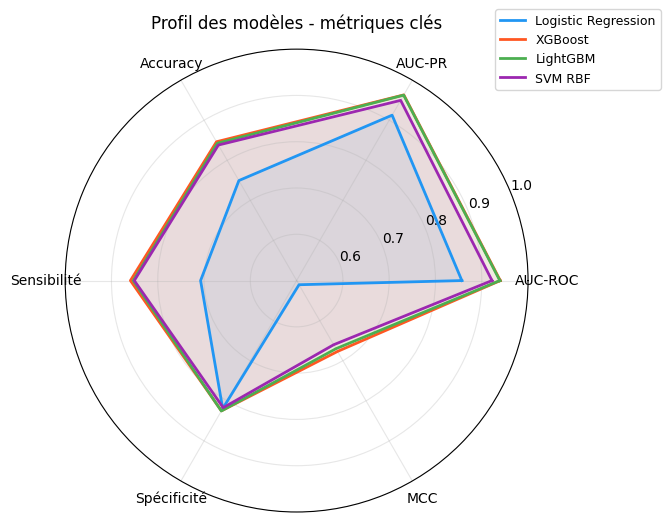

In [16]:
metrics_radar = ["AUC-ROC", "AUC-PR", "Accuracy", "Sensibilité",
                 "Spécificité", "MCC"]
N = len(metrics_radar)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig3, ax3 = plt.subplots(figsize=(7, 7),
                          subplot_kw=dict(polar=True))

for result, color in zip(all_results, colors):
    values = [result[m] for m in metrics_radar]
    values += values[:1]
    ax3.plot(angles, values, lw=2, color=color, label=result["Modèle"])
    ax3.fill(angles, values, color=color, alpha=0.08)

ax3.set_thetagrids(np.degrees(angles[:-1]), metrics_radar)
ax3.set_ylim(0.5, 1.0)
ax3.set_title("Profil des modèles - métriques clés", fontsize=12, pad=15)
ax3.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1), fontsize=9)
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("radar_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. VÉRIFICATION OVERFITTING - AUC TRAIN vs AUC TEST (modèles finaux)

In [17]:
print("\nVérification overfitting : modèles finaux")
print(f"{'─'*68}")
print(f"{'Modèle':<22}  {'AUC Train':>10}  {'AUC Test':>10}  "
      f"{'Gap':>8}  Verdict")
print(f"{'─'*68}")

for result in all_results:
    model  = result["_model"]
    name   = result["Modèle"]
    X_tr   = X_train_svm if name == "SVM RBF" else X_train
    y_tr   = y_train_svm if name == "SVM RBF" else y_train

    auc_tr = roc_auc_score(y_tr, model.predict_proba(X_tr)[:, 1])
    auc_te = result["AUC-ROC"]
    gap    = auc_tr - auc_te
    flag   = "OVERFITTING !" if gap > 0.05 else "OK"
    note   = " (sous-ens.)" if name == "SVM RBF" else ""

    print(f"{name:<22}  {auc_tr:>10.4f}  {auc_te:>10.4f}  "
          f"{gap:>8.4f}  {flag}{note}")

print(f"{'─'*68}")
print("Seuil : Gap > 0.05 donc surapprentissage potentiel.")


Vérification overfitting : modèles finaux
────────────────────────────────────────────────────────────────────
Modèle                   AUC Train    AUC Test       Gap  Verdict
────────────────────────────────────────────────────────────────────
Logistic Regression         0.8549      0.8570   -0.0021  OK
XGBoost                     0.9835      0.9400    0.0435  OK
LightGBM                    0.9770      0.9391    0.0379  OK
SVM RBF                     0.9444      0.9221    0.0223  OK (sous-ens.)
────────────────────────────────────────────────────────────────────
Seuil : Gap > 0.05 donc surapprentissage potentiel.


## 10. SAUVEGARDE DES MODÈLES

In [18]:
for result in all_results:
    name  = result["Modèle"].replace(" ", "_").lower()
    model = result["_model"]
    path  = f"modele_{name}.pkl"
    joblib.dump(model, path)
    print(f" Sauvegardé : {path}")

# Sauvegarde du tableau récapitulatif
df_results[cols_key].to_csv("resultats_comparaison.csv")
print("  Sauvegardé : resultats_comparaison.csv")

print("\nSauvegarde terminée")

 Sauvegardé : modele_logistic_regression.pkl
 Sauvegardé : modele_xgboost.pkl
 Sauvegardé : modele_lightgbm.pkl
 Sauvegardé : modele_svm_rbf.pkl
  Sauvegardé : resultats_comparaison.csv

Sauvegarde terminée


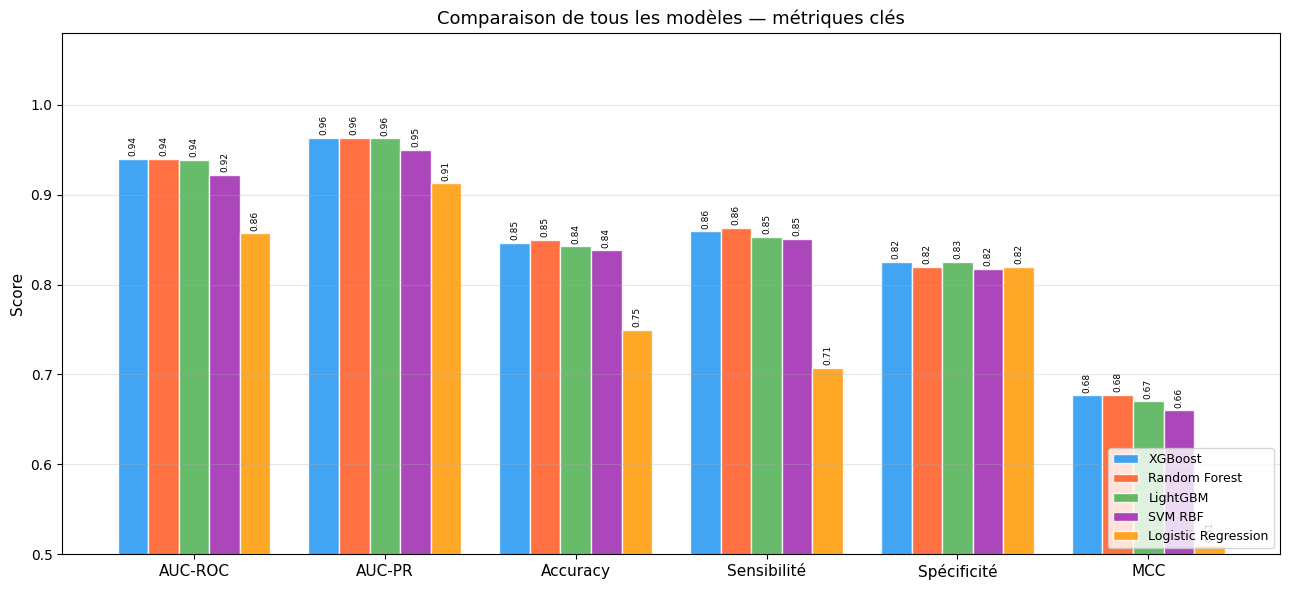


  TABLEAU FINAL — Tous les modèles (Random Forest inclus)
                     AUC-ROC       AUC IC95  AUC-PR  Accuracy  Sensibilité  Spécificité     MCC   Kappa   Brier
Modèle                                                                                                         
XGBoost               0.9400  0.9382–0.9418  0.9632    0.8463       0.8591       0.8250  0.6768  0.6761  0.0881
Random Forest         0.9397  0.9380–0.9415  0.9631    0.8500       0.8631       0.8200  0.6772  0.6767  0.0913
LightGBM              0.9391  0.9372–0.9409  0.9626    0.8426       0.8530       0.8253  0.6700  0.6690  0.0921
SVM RBF               0.9221  0.9198–0.9241  0.9496    0.8381       0.8507       0.8171  0.6601  0.6592  0.0992
Logistic Regression   0.8570  0.8543–0.8602  0.9126    0.7495       0.7075       0.8194  0.5104  0.4966  0.1486


In [19]:
# VISUALISATION COMPARATIVE — TOUS LES MODÈLES (RF inclus)

# Résultats du Random Forest (notebook précédent)
rf_result = {
    "Modèle"      : "Random Forest",
    "AUC-ROC"     : 0.9397,
    "AUC-PR"      : 0.9631,
    "Accuracy"    : 0.85,
    "Sensibilité" : 0.8631,
    "Spécificité" : 0.8200,
    "MCC"         : 0.6772,
    "Kappa"       : 0.6767,
    "Brier"       : 0.0913,
    "AUC IC95"    : "0.9380–0.9415",
    "MCC IC95"    : "0.6706–0.6830",
}

# Fusion avec les résultats des autres modèles
all_results_full = [{k: r[k] for k in metric_keys} for r in all_results]
all_results_full.append(rf_result)

df_all = pd.DataFrame(all_results_full).set_index("Modèle").sort_values(
    "AUC-ROC", ascending=False)

colors_all = ["#2196F3", "#FF5722", "#4CAF50", "#9C27B0", "#FF9800"]

# Barplot comparatif — métriques clés 
metrics_bar = ["AUC-ROC", "AUC-PR", "Accuracy", "Sensibilité",
               "Spécificité", "MCC"]

fig, ax = plt.subplots(figsize=(13, 6))
x     = np.arange(len(metrics_bar))
n_mod = len(df_all)
width = 0.8 / n_mod

for i, (model_name, row) in enumerate(df_all.iterrows()):
    offset = (i - n_mod / 2 + 0.5) * width
    bars   = ax.bar(x + offset,
                    [row[m] for m in metrics_bar],
                    width,
                    label=model_name,
                    color=colors_all[i],
                    alpha=0.85,
                    edgecolor='white')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.003,
                f"{h:.2f}", ha='center', va='bottom',
                fontsize=6.5, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(metrics_bar, fontsize=11)
ax.set_ylim(0.5, 1.08)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Comparaison de tous les modèles — métriques clés", fontsize=13)
ax.legend(fontsize=9, loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("comparaison_tous_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

# Tableau final complet 
print("\n" + "="*90)
print("  TABLEAU FINAL — Tous les modèles (Random Forest inclus)")
print("="*90)
print(df_all[["AUC-ROC", "AUC IC95", "AUC-PR", "Accuracy",
              "Sensibilité", "Spécificité", "MCC", "Kappa", "Brier"]].to_string())